<font size=15 color= orange><b>Sensibilidades y Análisis del Modelo  SIR  con Robustez vía Pérdida de Huber </b></font>

- Diego Marquez Franco


# Aproximación Numérica del Sistema Extendido

## Ejercicio 4

In [2]:
import numpy as np


In [ ]:

def SIR_extended(t, y, beta, gamma, N):
    S, I, R, I_beta, R_beta, I_gamma, R_gamma = y
    
    dS = -beta * S * I / N
    dI = beta * S * I / N - gamma * I
    dR = gamma * I
    
    dI_beta = (S * I / N) + beta * ((-(I_beta + R_beta) * I + S * I_beta) / N) - gamma * I_beta
    dR_beta = gamma * I_beta
    
    dI_gamma = -I + beta * ((-(I_gamma + R_gamma) * I + S * I_gamma) / N) - gamma * I_gamma
    dR_gamma = I + gamma * I_gamma
    
    return np.array([dS, dI, dR, dI_beta, dR_beta, dI_gamma, dR_gamma])

def J_extended(t, y, beta, gamma, N):
    S, I, R, I_beta, R_beta, I_gamma, R_gamma = y
    
    J = np.zeros((7, 7))
    
    J[0,0] = -beta * I / N
    J[0,1] = -beta * S / N
    
    J[1,0] = beta * I / N
    J[1,1] = beta * S / N - gamma
    
    J[2,1] = gamma
    
    J[3,0] = I/N + beta * I_beta / N
    J[3,1] = S/N + beta * (-I_beta - R_beta) / N
    J[3,3] = beta * (S - I) / N - gamma
    J[3,4] = -beta * I / N
    
    J[4,3] = gamma
    
    J[5,0] = beta * I_gamma / N
    J[5,1] = -1 + beta * (-I_gamma - R_gamma) / N
    J[5,5] = beta * (S - I) / N - gamma
    J[5,6] = -beta * I / N
    
    J[6,1] = 1
    J[6,5] = gamma
    
    return J

## Ejercicio 5

In [3]:

def newton_solver(G, JG, y0, tol=1e-5, max_iter=1000):
    y = y0.copy()
    
    for iteracion in range(max_iter):
        G_val = G(y)
        JG_val = JG(y)
        
        if np.linalg.norm(G_val) < tol:
            return y, iteracion + 1
        
        delta_y = np.linalg.solve(JG_val, -G_val)
        y += delta_y
    
    return y, max_iter

def euler_implicito_SIR(f, Jf, y0, t_span, h, params, use_explicit_guess=True):
    t0, tf = t_span
    n_pasos = int((tf - t0) / h) + 1
    t_valores = np.linspace(t0, tf, n_pasos)
    y_valores = np.zeros((n_pasos, len(y0)))
    y_valores[0] = y0
    
    iteraciones_totales_newton = 0
    
    for i in range(1, n_pasos):
        y_previo = y_valores[i-1]
        
        if use_explicit_guess:
            y_inicial = y_previo + h * f(t_valores[i-1], y_previo, *params)
        else:
            y_inicial = y_previo
        
        def G(y):
            return y - y_previo - h * f(t_valores[i], y, *params)
        
        def JG(y):
            return np.eye(len(y0)) - h * Jf(t_valores[i], y, *params)
        
        y_actual, iter_newton = newton_solver(G, JG, y_inicial)
        y_valores[i] = y_actual
        iteraciones_totales_newton += iter_newton
    
    return t_valores, y_valores, iteraciones_totales_newton

# Análisis de Convergencia y Eficiencia con el Paso Temporal h

In [4]:
import matplotlib.pyplot as plt

In [15]:
import numpy as np
import matplotlib.pyplot as plt

beta = 0.3
gamma = 0.1
N = 1.0
y0 = np.array([0.99, 0.01, 0.0, 0.0, 0.0, 0.0, 0.0])
t_span = [0, 100]

# 1. SOLUCIÓN DE REFERENCIA con href = 0.01

def generar_solucion_referencia(f, Jf, y0, t_span, href, params):

    t0, tf = t_span
    t_ref = np.arange(t0, tf + href, href)
    n_puntos = len(t_ref)
    y_ref = np.zeros((n_puntos, len(y0)))
    y_ref[0] = y0
    
    print(f" solución de referencia con href = {href}")
    print(f"Número de puntos temporales: {n_puntos}")
    
    for i in range(1, n_puntos):
        h_actual = t_ref[i] - t_ref[i-1]
        
        def G(y):
            return y - y_ref[i-1] - h_actual * f(t_ref[i], y, *params)
        
        def JG(y):
            return np.eye(len(y0)) - h_actual * Jf(t_ref[i], y, *params)
        
        y_guess = y_ref[i-1] + h_actual * f(t_ref[i-1], y_ref[i-1], *params)
        
        y_ref[i], _ = newton_solver(G, JG, y_guess)
        
        if i % 1000 == 0:
            print(f"Procesado paso {i}/{n_puntos}")
    
    print("Solución de referencia completada")
    return t_ref, y_ref

# 2. BARRIDO DE PASOS TEMPORALES

def ejecutar_barrido_pasos(f, Jf, y0, t_span, h_valores, params, t_ref, y_ref):

    resultados = {}
    
    print("\n barrido de pasos temporales")
    
    for h in h_valores:
        print(f"\nProcesando h = {h}")
        
        t_h, y_h, iter_totales = euler_implicito_SIR(f, Jf, y0, t_span, h, params)
        
        print(f"  - Iteraciones totales de Newton: {iter_totales}")
        print(f"  - Número de pasos temporales: {len(t_h)}")
        
        y_interp = np.zeros_like(y_h)
        for j in range(y_h.shape[1]):
            y_interp[:, j] = np.interp(t_h, t_ref, y_ref[:, j])
        
        error_cuadratico = np.zeros(len(t_h))
        for k in range(len(t_h)):
            error_cuadratico[k] = np.linalg.norm(y_h[k] - y_interp[k])**2
        
        E2 = np.sqrt(np.mean(error_cuadratico))
        
        resultados[h] = {
            't': t_h,
            'y': y_h,
            'iteraciones_totales': iter_totales,
            'iteraciones_promedio': iter_totales / len(t_h),
            'error_E2': E2,
            'y_interpolado': y_interp
        }
        
        print(f"  - Error E2(h): {E2:.6e}")
    
    return resultados

# 3. CÁLCULO DE MÉTRICAS DE ERROR

def calcular_metricas_detalladas(resultados):
 
    metricas = {}
    
    for h, datos in resultados.items():
        errores_componentes = []
        for comp in range(datos['y'].shape[1]):
            error_comp = np.sqrt(np.mean((datos['y'][:, comp] - datos['y_interpolado'][:, comp])**2))
            errores_componentes.append(error_comp)
        
        metricas[h] = {
            'error_E2': datos['error_E2'],
            'iteraciones_totales': datos['iteraciones_totales'],
            'iteraciones_promedio': datos['iteraciones_promedio'],
            'errores_componentes': errores_componentes,
            'n_pasos': len(datos['t'])
        }
    
    return metricas

# 4. ANÁLISIS DE ORDEN DE CONVERGENCIA

def analizar_orden_convergencia(metricas):
  
    h_valores = sorted(metricas.keys())
    errores = [metricas[h]['error_E2'] for h in h_valores]
    
    log_h = np.log10(h_valores)
    log_error = np.log10(errores)
    
    coeficientes = np.polyfit(log_h, log_error, 1)
    pendiente = coeficientes[0]
    orden_estimado = pendiente
    
    plt.figure(figsize=(10, 6))
    plt.plot(log_h, log_error, 'bo-', linewidth=2, markersize=8, label='Datos')
    
    x_tendencia = np.linspace(min(log_h), max(log_h), 100)
    y_tendencia = np.polyval(coeficientes, x_tendencia)
    plt.plot(x_tendencia, y_tendencia, 'r--', linewidth=1.5, 
             label=f'Tendencia (pendiente = {orden_estimado:.3f})')
    
    plt.xlabel('log₁₀(h)')
    plt.ylabel('log₁₀(E₂(h))')
    plt.title('Análisis de Orden de Convergencia\nMétodo de Euler Implícito')
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    for i, h in enumerate(h_valores):
        plt.annotate(f'h={h}', (log_h[i], log_error[i]), 
                    textcoords="offset points", xytext=(5,5), 
                    ha='left', fontsize=9)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\nORDEN DE CONVERGENCIA ESTIMADO: {orden_estimado:.3f}")
    print("(Valor esperado ≈ 1 para Euler Implícito)")
    
    return orden_estimado

# 5. ANÁLISIS DE EFICIENCIA Y BALANCE

def analizar_eficiencia_balance(metricas):
  
    h_valores = sorted(metricas.keys())
    errores = [metricas[h]['error_E2'] for h in h_valores]
    iter_totales = [metricas[h]['iteraciones_totales'] for h in h_valores]
    iter_promedio = [metricas[h]['iteraciones_promedio'] for h in h_valores]
    
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))
    
    ax1.semilogy(h_valores, errores, 'ro-', linewidth=2, markersize=8)
    ax1.set_xlabel('Paso temporal h')
    ax1.set_ylabel('Error E₂(h) (escala log)')
    ax1.set_title('Error vs Paso Temporal')
    ax1.grid(True, alpha=0.3)
    for i, h in enumerate(h_valores):
        ax1.annotate(f'h={h}', (h_valores[i], errores[i]), 
                    textcoords="offset points", xytext=(0,10), ha='center')
    
    ax2.plot(h_valores, iter_totales, 'go-', linewidth=2, markersize=8)
    ax2.set_xlabel('Paso temporal h')
    ax2.set_ylabel('Iteraciones totales de Newton')
    ax2.set_title('Costo Computacional vs Paso Temporal')
    ax2.grid(True, alpha=0.3)
    for i, h in enumerate(h_valores):
        ax2.annotate(f'h={h}', (h_valores[i], iter_totales[i]), 
                    textcoords="offset points", xytext=(0,10), ha='center')
    
    ax3.loglog(iter_totales, errores, 'bo-', linewidth=2, markersize=8)
    ax3.set_xlabel('Iteraciones totales de Newton')
    ax3.set_ylabel('Error E₂(h)')
    ax3.set_title('Balance: Precisión vs Costo Computacional')
    ax3.grid(True, alpha=0.3)
    for i, h in enumerate(h_valores):
        ax3.annotate(f'h={h}', (iter_totales[i], errores[i]), 
                    textcoords="offset points", xytext=(5,5), ha='left')
    
    ax4.plot(h_valores, iter_promedio, 'mo-', linewidth=2, markersize=8)
    ax4.set_xlabel('Paso temporal h')
    ax4.set_ylabel('Iteraciones promedio por paso')
    ax4.set_title('Eficiencia del Método de Newton por Paso')
    ax4.grid(True, alpha=0.3)
    for i, h in enumerate(h_valores):
        ax4.annotate(f'{iter_promedio[i]:.2f}', (h_valores[i], iter_promedio[i]), 
                    textcoords="offset points", xytext=(0,10), ha='center')
    
    plt.tight_layout()
    plt.show()

# 6. REPORTE Y CONCLUSIONES

def generar_reporte_final(metricas):
 
    h_valores = sorted(metricas.keys())
    
    
    print(" ANÁLISIS DE CONVERGENCIA Y EFICIENCIA")

    print(f"{'h':>8} {'E₂(h)':>12} {'Iter Totales':>15} {'Iter/Paso':>12} {'Cumple E₂<0.01':>15}")

    
    mejor_h = None
    mejor_balance = float('inf')
    candidatos = []
    
    for h in h_valores:
        datos = metricas[h]
        error = datos['error_E2']
        iter_tot = datos['iteraciones_totales']
        iter_prom = datos['iteraciones_promedio']
        cumple_criterio = error < 0.01
        
        balance_metric = error * iter_tot / 1000
        
        marca = "✓" if cumple_criterio else "✗"
        
        print(f"{h:>8.3f} {error:>12.6f} {iter_tot:>15} {iter_prom:>12.2f} {marca:>15}")
        
        if cumple_criterio:
            candidatos.append((h, balance_metric, iter_tot, error))
            if balance_metric < mejor_balance:
                mejor_balance = balance_metric
                mejor_h = h
    

    
    print("\nCONCLUSIONES:")

    
    if mejor_h is not None:
        mejor_datos = metricas[mejor_h]
        print(f" MEJOR BALANCE IDENTIFICADO: h = {mejor_h}")
        print(f"  - Error E₂(h): {mejor_datos['error_E2']:.6f} (< 0.01 ✓)")
        print(f"  - Iteraciones totales: {mejor_datos['iteraciones_totales']}")
        print(f"  - Iteraciones por paso: {mejor_datos['iteraciones_promedio']:.2f}")
        print(f"  - Justificación: Combina precisión aceptable con costo computacional moderado")
    else:
        print(" No se encontró un paso h que cumpla con E₂(h) < 0.01")
        h_menor_error = min(metricas.keys(), key=lambda h: metricas[h]['error_E2'])
        datos_menor_error = metricas[h_menor_error]
        print(f" Alternativa recomendada: h = {h_menor_error}")
        print(f"   Error E₂(h): {datos_menor_error['error_E2']:.6f}")
    
    print("\nANÁLISIS ADICIONAL:")
    for h in h_valores:
        datos = metricas[h]
        print(f"h = {h}: {datos['n_pasos']} pasos, {datos['iteraciones_promedio']:.2f} iter/paso")
    
    return mejor_h

ANÁLISIS DE CONVERGENCIA Y EFICIENCIA

solución de referencia.
 solución de referencia con href = 0.01
Número de puntos temporales: 10001
Procesado paso 1000/10001
Procesado paso 2000/10001
Procesado paso 3000/10001
Procesado paso 4000/10001
Procesado paso 5000/10001
Procesado paso 6000/10001
Procesado paso 7000/10001
Procesado paso 8000/10001
Procesado paso 9000/10001
Procesado paso 10000/10001
Solución de referencia completada

barrido de pasos temporales

 barrido de pasos temporales

Procesando h = 0.5
  - Iteraciones totales de Newton: 400
  - Número de pasos temporales: 201
  - Error E2(h): 1.487590e-01

Procesando h = 0.25
  - Iteraciones totales de Newton: 800
  - Número de pasos temporales: 401
  - Error E2(h): 7.621793e-02

Procesando h = 0.1
  - Iteraciones totales de Newton: 1851
  - Número de pasos temporales: 1001
  - Error E2(h): 3.235075e-02

Procesando h = 0.05
  - Iteraciones totales de Newton: 3067
  - Número de pasos temporales: 2001
  - Error E2(h): 1.773271e-02

 

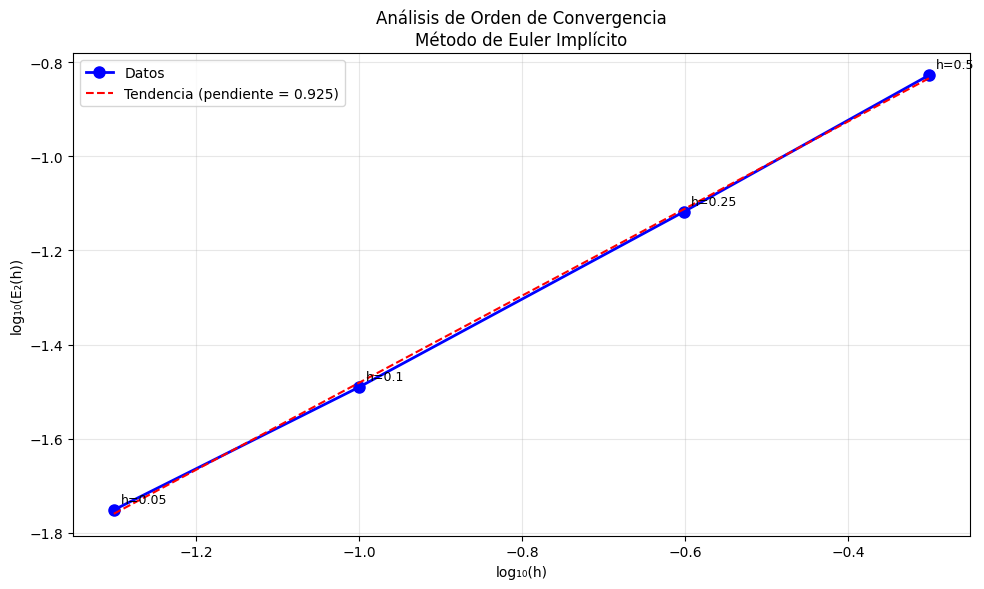


ORDEN DE CONVERGENCIA ESTIMADO: 0.925
(Valor esperado ≈ 1 para Euler Implícito)

 análisis de eficiencia y balance


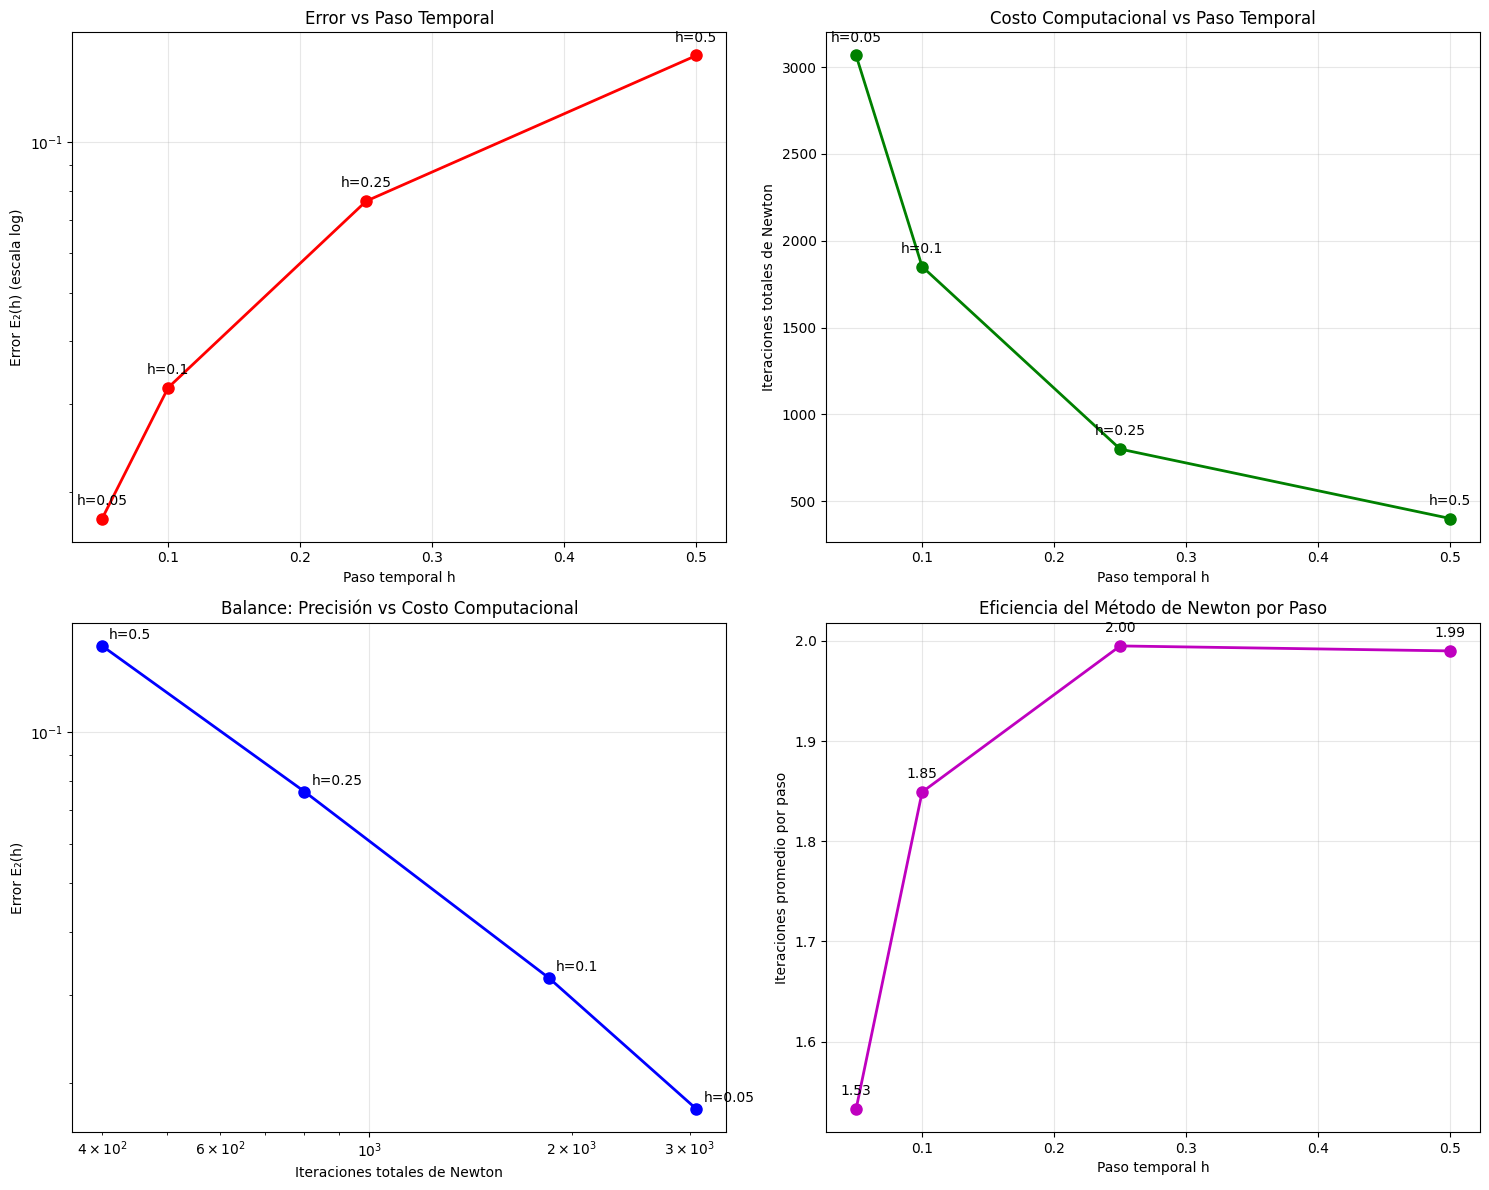

 ANÁLISIS DE CONVERGENCIA Y EFICIENCIA
       h        E₂(h)    Iter Totales    Iter/Paso  Cumple E₂<0.01
   0.050     0.017733            3067         1.53               ✗
   0.100     0.032351            1851         1.85               ✗
   0.250     0.076218             800         2.00               ✗
   0.500     0.148759             400         1.99               ✗

CONCLUSIONES:
 No se encontró un paso h que cumpla con E₂(h) < 0.01
 Alternativa recomendada: h = 0.05
   Error E₂(h): 0.017733

ANÁLISIS ADICIONAL:
h = 0.05: 2001 pasos, 1.53 iter/paso
h = 0.1: 1001 pasos, 1.85 iter/paso
h = 0.25: 401 pasos, 2.00 iter/paso
h = 0.5: 201 pasos, 1.99 iter/paso


In [16]:
def ejecutar_analisis_completo():

    print("ANÁLISIS DE CONVERGENCIA Y EFICIENCIA")
    
    params = (beta, gamma, N)
    h_valores = [0.5, 0.25, 0.1, 0.05]
    href = 0.01
    
    print("\nsolución de referencia.")
    t_ref, y_ref = generar_solucion_referencia(
        SIR_extended, J_extended, y0, t_span, href, params
    )
    
    print("\nbarrido de pasos temporales")
    resultados = ejecutar_barrido_pasos(
        SIR_extended, J_extended, y0, t_span, h_valores, params, t_ref, y_ref
    )
    
    print("\n métricas de error")
    metricas = calcular_metricas_detalladas(resultados)
    
    print("\nanálisis de orden de convergencia")
    orden = analizar_orden_convergencia(metricas)
    
    print("\n análisis de eficiencia y balance")
    analizar_eficiencia_balance(metricas)
    

    mejor_h = generar_reporte_final(metricas)
    


    
    return resultados, metricas, mejor_h

resultados, metricas, mejor_h = ejecutar_analisis_completo()

# Visualización del Campo de Descenso (Quiver Map)

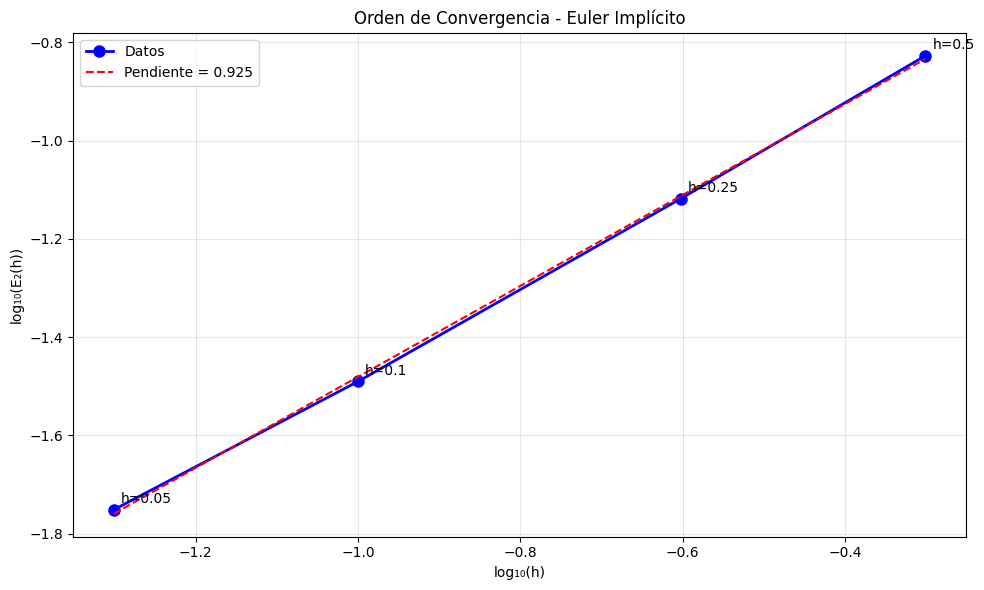

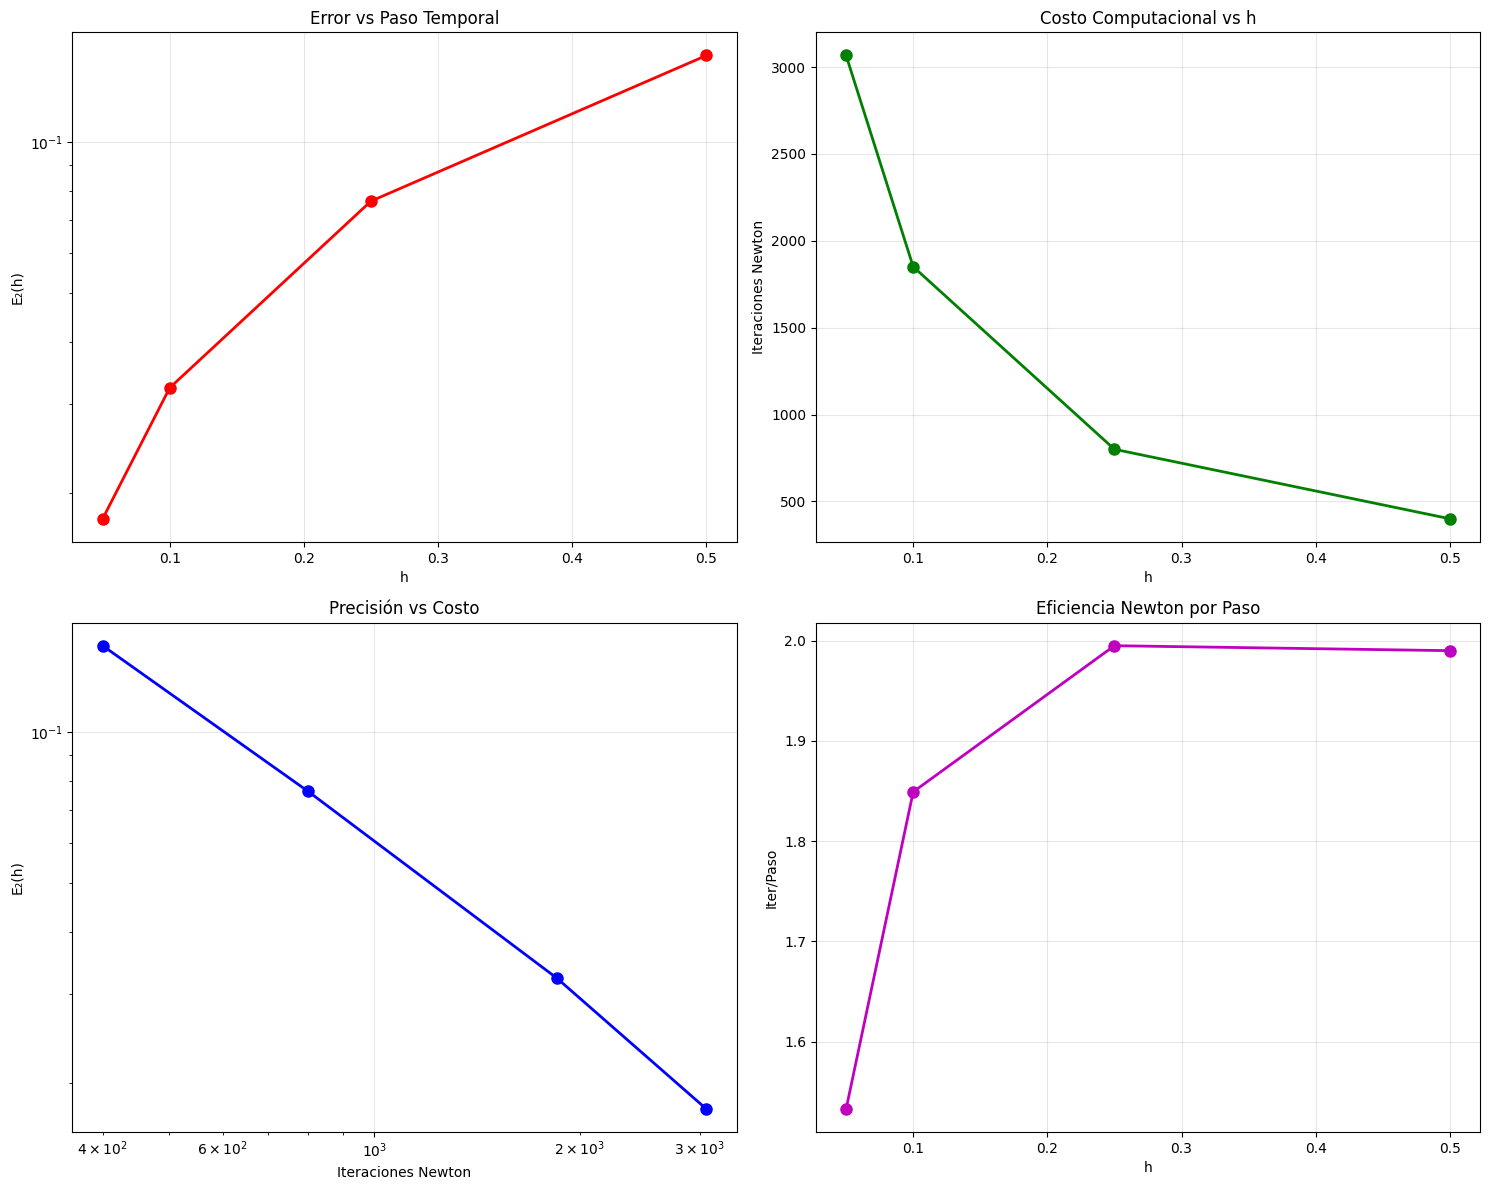

ANÁLISIS DE CONVERGENCIA Y EFICIENCIA
       h        E₂(h)    Iter Totales    Iter/Paso    E₂<0.01
   0.050     0.017733            3067         1.53          ✗
   0.100     0.032351            1851         1.85          ✗
   0.250     0.076218             800         2.00          ✗
   0.500     0.148759             400         1.99          ✗

RECOMENDADO: h = 0.05


In [17]:
import numpy as np
import matplotlib.pyplot as plt

beta = 0.3
gamma = 0.1
N = 1.0
y0 = np.array([0.99, 0.01, 0.0, 0.0, 0.0, 0.0, 0.0])
t_span = [0, 100]

def generar_solucion_referencia(f, Jf, y0, t_span, href, params):
    t0, tf = t_span
    t_ref = np.arange(t0, tf + href, href)
    n_puntos = len(t_ref)
    y_ref = np.zeros((n_puntos, len(y0)))
    y_ref[0] = y0
    
    for i in range(1, n_puntos):
        h_actual = t_ref[i] - t_ref[i-1]
        
        def G(y):
            return y - y_ref[i-1] - h_actual * f(t_ref[i], y, *params)
        
        def JG(y):
            return np.eye(len(y0)) - h_actual * Jf(t_ref[i], y, *params)
        
        y_guess = y_ref[i-1] + h_actual * f(t_ref[i-1], y_ref[i-1], *params)
        y_ref[i], _ = newton_solver(G, JG, y_guess)
    
    return t_ref, y_ref

def ejecutar_barrido_pasos(f, Jf, y0, t_span, h_valores, params, t_ref, y_ref):
    resultados = {}
    
    for h in h_valores:
        t_h, y_h, iter_totales = euler_implicito_SIR(f, Jf, y0, t_span, h, params)
        
        y_interp = np.zeros_like(y_h)
        for j in range(y_h.shape[1]):
            y_interp[:, j] = np.interp(t_h, t_ref, y_ref[:, j])
        
        error_cuadratico = np.zeros(len(t_h))
        for k in range(len(t_h)):
            error_cuadratico[k] = np.linalg.norm(y_h[k] - y_interp[k])**2
        
        E2 = np.sqrt(np.mean(error_cuadratico))
        
        resultados[h] = {
            't': t_h,
            'y': y_h,
            'iteraciones_totales': iter_totales,
            'iteraciones_promedio': iter_totales / len(t_h),
            'error_E2': E2,
            'y_interpolado': y_interp
        }
    
    return resultados

def calcular_metricas_detalladas(resultados):
    metricas = {}
    
    for h, datos in resultados.items():
        errores_componentes = []
        for comp in range(datos['y'].shape[1]):
            error_comp = np.sqrt(np.mean((datos['y'][:, comp] - datos['y_interpolado'][:, comp])**2))
            errores_componentes.append(error_comp)
        
        metricas[h] = {
            'error_E2': datos['error_E2'],
            'iteraciones_totales': datos['iteraciones_totales'],
            'iteraciones_promedio': datos['iteraciones_promedio'],
            'errores_componentes': errores_componentes,
            'n_pasos': len(datos['t'])
        }
    
    return metricas

def analizar_orden_convergencia(metricas):
    h_valores = sorted(metricas.keys())
    errores = [metricas[h]['error_E2'] for h in h_valores]
    
    log_h = np.log10(h_valores)
    log_error = np.log10(errores)
    
    coeficientes = np.polyfit(log_h, log_error, 1)
    pendiente = coeficientes[0]
    
    plt.figure(figsize=(10, 6))
    plt.plot(log_h, log_error, 'bo-', linewidth=2, markersize=8, label='Datos')
    
    x_tendencia = np.linspace(min(log_h), max(log_h), 100)
    y_tendencia = np.polyval(coeficientes, x_tendencia)
    plt.plot(x_tendencia, y_tendencia, 'r--', linewidth=1.5, 
             label=f'Pendiente = {pendiente:.3f}')
    
    plt.xlabel('log₁₀(h)')
    plt.ylabel('log₁₀(E₂(h))')
    plt.title('Orden de Convergencia - Euler Implícito')
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    for i, h in enumerate(h_valores):
        plt.annotate(f'h={h}', (log_h[i], log_error[i]), 
                    textcoords="offset points", xytext=(5,5), ha='left')
    
    plt.tight_layout()
    plt.show()
    
    return pendiente

def analizar_eficiencia_balance(metricas):
    h_valores = sorted(metricas.keys())
    errores = [metricas[h]['error_E2'] for h in h_valores]
    iter_totales = [metricas[h]['iteraciones_totales'] for h in h_valores]
    iter_promedio = [metricas[h]['iteraciones_promedio'] for h in h_valores]
    
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))
    
    ax1.semilogy(h_valores, errores, 'ro-', linewidth=2, markersize=8)
    ax1.set_xlabel('h')
    ax1.set_ylabel('E₂(h)')
    ax1.set_title('Error vs Paso Temporal')
    ax1.grid(True, alpha=0.3)
    
    ax2.plot(h_valores, iter_totales, 'go-', linewidth=2, markersize=8)
    ax2.set_xlabel('h')
    ax2.set_ylabel('Iteraciones Newton')
    ax2.set_title('Costo Computacional vs h')
    ax2.grid(True, alpha=0.3)
    
    ax3.loglog(iter_totales, errores, 'bo-', linewidth=2, markersize=8)
    ax3.set_xlabel('Iteraciones Newton')
    ax3.set_ylabel('E₂(h)')
    ax3.set_title('Precisión vs Costo')
    ax3.grid(True, alpha=0.3)
    
    ax4.plot(h_valores, iter_promedio, 'mo-', linewidth=2, markersize=8)
    ax4.set_xlabel('h')
    ax4.set_ylabel('Iter/Paso')
    ax4.set_title('Eficiencia Newton por Paso')
    ax4.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

def generar_reporte_final(metricas):
    h_valores = sorted(metricas.keys())
    
    print("ANÁLISIS DE CONVERGENCIA Y EFICIENCIA")
    print(f"{'h':>8} {'E₂(h)':>12} {'Iter Totales':>15} {'Iter/Paso':>12} {'E₂<0.01':>10}")
    
    mejor_h = None
    mejor_balance = float('inf')
    
    for h in h_valores:
        datos = metricas[h]
        error = datos['error_E2']
        iter_tot = datos['iteraciones_totales']
        iter_prom = datos['iteraciones_promedio']
        cumple_criterio = error < 0.01
        
        balance_metric = error * iter_tot
        
        marca = "✓" if cumple_criterio else "✗"
        print(f"{h:>8.3f} {error:>12.6f} {iter_tot:>15} {iter_prom:>12.2f} {marca:>10}")
        
        if cumple_criterio and balance_metric < mejor_balance:
            mejor_balance = balance_metric
            mejor_h = h
    
    if mejor_h is not None:
        mejor_datos = metricas[mejor_h]
        print(f"\nMEJOR h: {mejor_h}")
        print(f"Error: {mejor_datos['error_E2']:.6f}")
        print(f"Iteraciones: {mejor_datos['iteraciones_totales']}")
    else:
        h_menor_error = min(metricas.keys(), key=lambda h: metricas[h]['error_E2'])
        print(f"\nRECOMENDADO: h = {h_menor_error}")
    
    return mejor_h

def ejecutar_analisis_completo():
    params = (beta, gamma, N)
    h_valores = [0.5, 0.25, 0.1, 0.05]
    href = 0.01
    
    t_ref, y_ref = generar_solucion_referencia(SIR_extended, J_extended, y0, t_span, href, params)
    resultados = ejecutar_barrido_pasos(SIR_extended, J_extended, y0, t_span, h_valores, params, t_ref, y_ref)
    metricas = calcular_metricas_detalladas(resultados)
    orden = analizar_orden_convergencia(metricas)
    analizar_eficiencia_balance(metricas)
    mejor_h = generar_reporte_final(metricas)
    
    return resultados, metricas, mejor_h

resultados, metricas, mejor_h = ejecutar_analisis_completo()